# Домашнее задание 1

**Денисов Егор Александрович, 517 группа**

## Данные

**BeerAdvocate / Multi-aspect Reviews** — отзывы пользователей о пиве.
[Страница источника](https://cseweb.ucsd.edu/~jmcauley/datasets.html#multi_aspect)

Фактически загруженный файл содержит **1 586 614 отзывов, 33 387 пользователей и 66 055 напитков**.
В исходном файле 104 стиля и 5840 производителей. В качестве записи выступает опубликованный отзыв.
Расшифровка полей исходного датасета приведена ниже.

| Исходное поле | Смысл |
|---|---|
| `beer/beerId` | Идентификатор напитка |
| `beer/name` | Название напитка |
| `beer/brewerId` | Производитель |
| `beer/style` | Вид напитка |
| `beer/ABV` | Крепость, % |
| `review/profileName` | Пользователь |
| `review/overall` | Рейтинг |
| `review/time` | Unix timestamp публикации, секунды |
| `review/appearance`, `review/aroma`, `review/palate`, `review/taste` | Оценки разных свойств напитка |
| `review/text` | Текст отзыва |

Рекомендуем **новые для пользователя напитки**. Релевантный объект - напиток,
получивший в соответствующем отложенном периоде реальную оценку **не ниже 4**.
Этот критерий одинаков для всех моделей независимо от их обучающей цели.
Аспектные оценки и текст будущего отзыва недоступны в момент рекомендации и не включаются в признаки.

In [32]:
import gc

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from models import ItemKNN, ImplicitALS, SLIM, FactorizationMachine, TimeSVDPlusPlus
from utils import (seed_everything, download_beer, read_beer, clean_reviews,
                   prepare_split, make_train_data, relevance_sets, history_mask,
                   tune_model, evaluate)

In [33]:
SEED, K = 52, 10
PRIMARY_METRIC = 'NDCG@10'

seed_everything(SEED)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.precision', 3)
pd.set_option('display.float_format', '{:.3f}'.format)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})

In [34]:
raw = read_beer(download_beer())
print(f'Dataset len: {len(raw)}')
print(f'Unique users: {raw.user_id.nunique()}')
print(f'Unique items: {raw.item_id.nunique()}')
display(raw.head())

Dataset len: 1586614
Unique users: 33387
Unique items: 66055


,user_id,item_id,rating,timestamp,name,style,brewery,abv
0,stcules,47986,1.500,1234817823,Sausa Weizen,Hefeweizen,10325,5.000
1,stcules,48213,3.000,1235915097,Red Moon,English Strong Ale,10325,6.200
2,stcules,48215,3.000,1235916604,Black Horse Black Beer,Foreign / Export Stout,10325,6.500
3,stcules,47969,3.000,1234725145,Sausa Pils,German Pilsener,10325,5.000
4,johnmichaelsen,64883,4.000,1293735206,Cauldron DIPA,American Double / Imperial IPA,1075,7.700


Посмотрим на типы данных и пропуски в них.

In [35]:
display(raw.dtypes.rename('dtype').to_frame().join(raw.isna().sum().rename('missing')))

,dtype,missing
user_id,string[python],348
item_id,int64,0
rating,float64,0
timestamp,int64,0
name,string[python],0
style,string[python],0
brewery,string[python],0
abv,float64,67785


Выведем некоторые статистики по датасету.

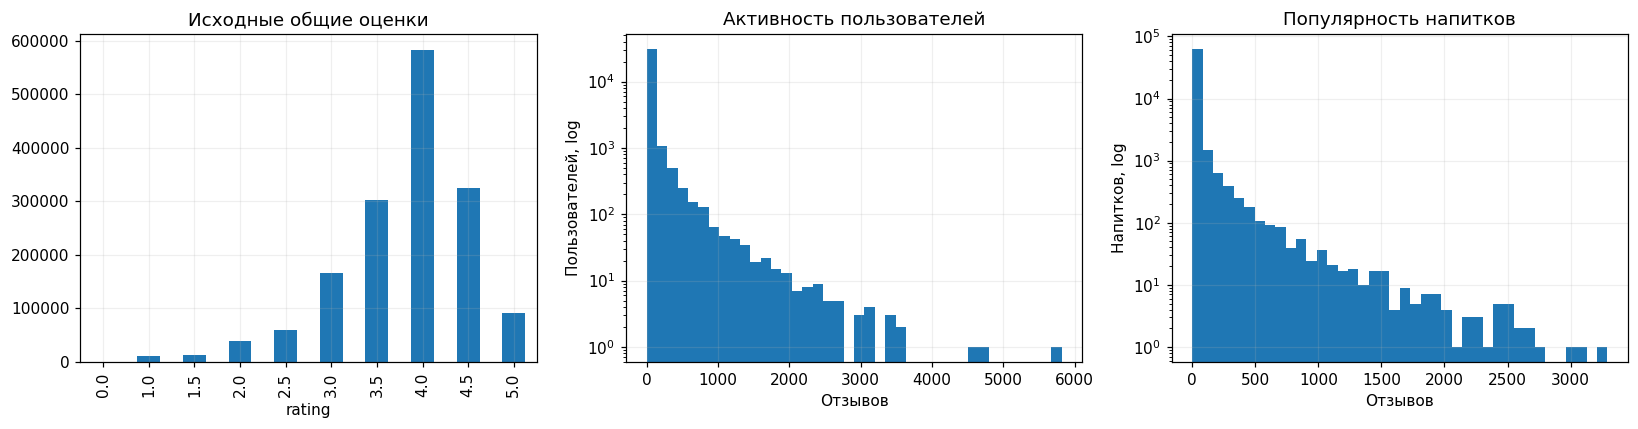

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
raw.rating.value_counts().sort_index().plot.bar(ax=axes[0], title='Исходные общие оценки')
axes[1].hist(raw.groupby('user_id').size(), bins=40, log=True)
axes[1].set(title='Активность пользователей', xlabel='Отзывов', ylabel='Пользователей, log')
axes[2].hist(raw.groupby('item_id').size(), bins=40, log=True)
axes[2].set(title='Популярность напитков', xlabel='Отзывов', ylabel='Напитков, log')

fig.tight_layout()
plt.show()

## Предобработка

Удаляем записи без пользователя, объекта, времени или допустимой оценки, приводим все поля к нужному типу данных. Некорректный ABV заменяем пропуском. Для каждой пары `(user, item)` сохраняем
самый ранний отзыв. Удаляется **355 некорректных записей** и **14 786 повторных отзывов**,
остаётся **1 571 473 взаимодействия**.

Используем временное разбиение с непересекающимися группами пользователей validation и test.
Временная граница - 70-й процентиль timestamp очищенного корпуса. В train входят только отзывы, опубликованные до этой временной отметки.
По этой train-части выбираем до **1200** самых популярных напитков с минимум 15 отзывами,
затем до **4000** самых активных пользователей с минимум 10 отзывами и 3 положительными оценками.

Обе отложенные выборки охватывают один будущий период, validation не является отдельным более ранним
временным окном. Validation используется для подбора гиперпараметров, test - только для финальной оценки качества работы модели.

| Подвыборка | Отзывов |
|---|---:|
| Train | 518,712 |
| Validation | 32,451 |
| Test | 34,372 |
| Всего | 585,535 |

Всего сохраняются **585 535 взаимодействий**, **4000 пользователей** и **1200 напитков**.

Для удобной работы с тренировочной подвыборкой реализован вспомогательный класс `TrainData` - он хранит только train: массивы ID, оценок и timestamps, метапризнаки и размеры каталога.
При создании он один раз вычисляет среднюю оценку, бинарные положительные взаимодействия, маску всех известных пар, матрицу оценок, отсортированные положительные истории.

In [37]:
CONFIG = dict(max_users=4000, max_items=1200, train_fraction=.70,
              validation_user_fraction=.5, min_user_train=10,
              min_user_positives=3, min_item_train=15, threshold=4.0, seed=SEED)

clean, cleaning_report = clean_reviews(raw)
del raw
gc.collect()

3449

In [38]:
sample, train, validation, test, metadata, split_report = prepare_split(clean, **CONFIG)

display(pd.DataFrame([{'part': name, 'reviews': len(frame),
                       'users_with_reviews': frame.user_idx.nunique(),
                       'items': frame.item_idx.nunique(),
                       'first_utc': pd.to_datetime(frame.timestamp.min(), unit='s', utc=True),
                       'last_utc': pd.to_datetime(frame.timestamp.max(), unit='s', utc=True)}
                      for name, frame in [('train', train), ('validation', validation), ('test', test)]]))

print('Разреженность всей подвыборки:', f"{1-split_report['density']:.3%}")

del clean
gc.collect()

,part,reviews,users_with_reviews,items,first_utc,last_utc
0,train,518712,4000,1200,1998-01-10 00:00:01+00:00,2010-07-23 01:55:04+00:00
1,validation,32451,939,1182,2010-07-23 01:56:53+00:00,2012-01-11 09:00:38+00:00
2,test,34372,998,1177,2010-07-23 02:18:24+00:00,2012-01-11 08:32:54+00:00


Разреженность всей подвыборки: 87.801%


0

In [39]:
data, feature_report = make_train_data(train, metadata, threshold=CONFIG['threshold'])
display(pd.Series(feature_report, name='Метапризнаки train').to_frame())

print('Положительных train-отзывов:', int(data.positive_mask.sum()))
print(f'Средний рейтинг на train: {data.ratings.mean():.3f}')

,Метапризнаки train
style_categories,93
brewery_categories,295
abv_imputation_median,6.500
abv_mean,7.077
abv_std,2.357
abv_missing_fraction,0.001
feature_names,"[style_one_hot, brewery_one_hot, standardized_ABV]"


Положительных train-отзывов: 348779
Средний рейтинг на train: 3.887


In [40]:
t_val, t_test = split_report['validation_start'], split_report['test_start']

train_seen = history_mask(data)
positive_counts = data.positives.sum(dim=1).numpy()
remaining = data.n_items - data.seen.sum(dim=1).numpy()
eligible_users = np.flatnonzero((positive_counts >= 3) & (remaining >= K))

validation_users = np.intersect1d(eligible_users, split_report['validation_user_ids'])
test_users = np.intersect1d(eligible_users, split_report['test_user_ids'])
validation_truth = relevance_sets(validation, validation_users, CONFIG['threshold'])

Посмотрим распределение оценок в получившейся тренировочной подвыборке.

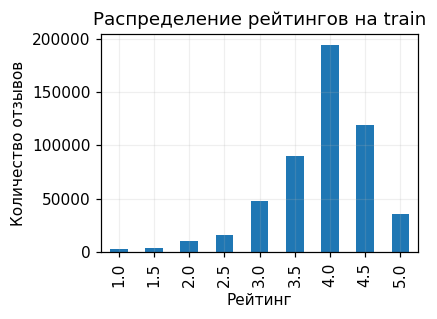

In [41]:
fig, ax = plt.subplots(figsize=(4, 3))
train.rating.value_counts().sort_index().plot.bar(ax=ax)

ax.set(title='Распределение рейтингов на train',
       xlabel='Рейтинг', ylabel='Количество отзывов')

fig.tight_layout()
plt.show()

## Модели

Для унифицированного интерфейса работы с моделями был реализован общий базовый класс — `BaseRecommender(torch.nn.Module)`.
Каждая модель отдельно переопределяет метод `fit`, в котором реализуется обучение.
Для FM и timeSVD++ в нее передаются параметры `loss, optimizer`. У ItemKNN, iALS и SLIM метод `fit()` не принимает аргументов.

Вспомогательная функция `tune_model` перебирает гиперпараметры модели, выбирая лучшие по NDCG@10 на валидации (используем Recall@10 как вторую метрику, по которой оцениваем при равенстве NDCG@10). Метод `score` возвращает предсказания модели; `recommend` - отранжированные объекты для рекомендации.

In [42]:
def plot_losses(models, xlabel, ylabel, start=1):
    for name, model in models.items():
        steps = np.arange(start, start + len(model.loss_history))
        plt.plot(steps, model.loss_history, marker='.', label=name)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.gca().yaxis.set_major_formatter('{x:.3f}')
    plt.legend()
    plt.tight_layout()
    plt.show()

### ItemKNN

Центрируем явные оценки пользователя: $d_{ui}=r_{ui}-\bar r_u$ на известных парах,
иначе $d_{ui}=0$. Обозначим $U_{ij}=U_i\cap U_j$ и будем считать сходство двух айтемов по следующей формуле:
$$s_{ij}=\frac{\sum_{u\in U_{ij}}d_{ui}d_{uj}}
{\sqrt{\sum_{u\in U_{ij}}d_{ui}^2}\sqrt{\sum_{u\in U_{ij}}d_{uj}^2}}.$$
Оставляем `n_neighbors` соседей с наибольшим сходством, предсказание модели вычисляем как:
$$\hat r_{ui}=\bar r_u+\frac{\sum_{j\in I_u\cap N(i)}s_{ji}(r_{uj}-\bar r_u)}
{\sum_{j\in I_u\cap N(i)}|s_{ji}|}.$$
При отсутствии вклада соседей возвращается средняя оценка пользователя.

**Гиперпараметры ItemKNN.** Сравниваем 50 и 150 соседей на целевой объект.
Выбираем конфигурацию по validation NDCG@10; при равенстве - по Recall@10.

In [43]:
knn_grid = [dict(n_neighbors=50), dict(n_neighbors=150)]

knn, knn_choice, knn_trials = tune_model('ItemKNN', ItemKNN, knn_grid, data,
    validation_truth, validation_users, t_val, train_seen, seed=SEED)

display(knn_trials)

ItemKNN 1/2: NDCG@10=0.02029, Recall@10=0.00727
ItemKNN 2/2: NDCG@10=0.01825, Recall@10=0.00617


,model,trial,parameters,fit_seconds,NDCG@10,Recall@10
0,ItemKNN,1,{'n_neighbors': 50},0.051,0.020,0.007
1,ItemKNN,2,{'n_neighbors': 150},0.049,0.018,0.006


### iALS

Положим $s_{ui} = \begin{cases} 1, \quad r_{ui} \geq 4 \\ -1, \quad r_{ui} < 4 \\ 0, \quad r_{ui} \notin R \end{cases}$

Предпочтение $p_{ui}=\mathbb{1}[s_{ui}>0]$, confidence $c_{ui}=1+\alpha|s_{ui}|$.

Loss:
$$L=\sum_{u,i}c_{ui}(p_{ui}-a_u^Tb_i)^2+
\lambda\left(\sum_u C_u\|a_u\|^2+\sum_i C_i\|b_i\|^2\right).$$
Веса регуляризации: $C_u=n_u/\overline n_u$, $C_i=n_i/\overline n_i$, где n - число всех train-отзывов. Оптимум находится попеременным фиксированием одной матрицы и решением лийнейной системы для другой.

**Гиперпараметры iALS.** Сравниваем два сочетания:
 * rank = 16, $\alpha = 10$, $\lambda = 1$, 10 итераций
 * rank = 32, $\alpha = 30$, $\lambda = 3$, 15 итераций.

Критерий выбора - validation NDCG@10, затем Recall@10.

In [44]:
ials_grid = [dict(n_factors=16, alpha=10., regularization=1., n_iterations=10),
             dict(n_factors=32, alpha=30., regularization=3., n_iterations=15)]

ials, ials_choice, ials_trials = tune_model('iALS', ImplicitALS, ials_grid, data,
    validation_truth, validation_users, t_val, train_seen, seed=SEED)

display(ials_trials)

iALS 1/2: NDCG@10=0.06747, Recall@10=0.02800
iALS 2/2: NDCG@10=0.04476, Recall@10=0.01752


,model,trial,parameters,fit_seconds,NDCG@10,Recall@10
0,iALS,1,"{'n_factors': 16, 'alpha': 10.0, 'regularization': 1.0, 'n_iterations': 10}",0.844,0.067,0.028
1,iALS,2,"{'n_factors': 32, 'alpha': 30.0, 'regularization': 3.0, 'n_iterations': 15}",3.304,0.045,0.018


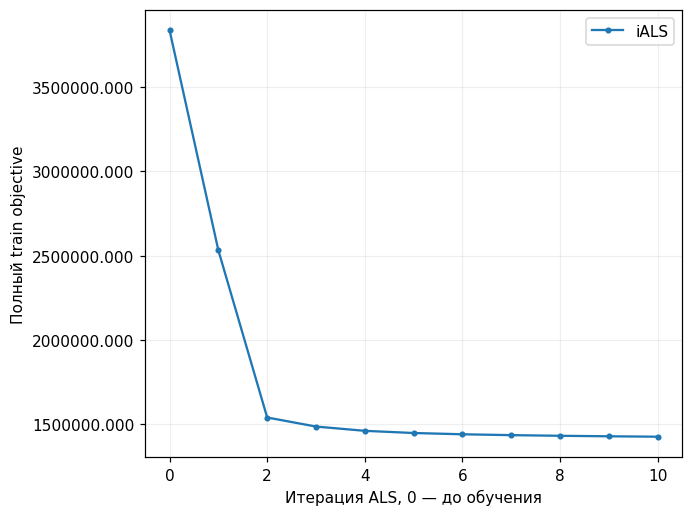

In [45]:
plot_losses({'iALS': ials}, 'Итерация ALS, 0 — до обучения', 'Полный train objective', start=0)

### SLIM

Для бинарной матрицы положительных взаимодействий A обучаем матрицу связей W:
$$L(W)=\frac12\|A-AW\|_F^2+\lambda_1\|W\|_1+
\frac{\lambda_2}{2}\|W\|_F^2,\qquad W\ge0,\quad diag(W)=0.$$
L1 зануляет часть весов, L2 ограничивает их величину; нулевая диагональ запрещает копирование
объекта в самого себя.

Для $G=A^TA$ точное покоординатное обновление:
$$W_{ji}\leftarrow\max\left(0,
\frac{G_{ji}-\sum_{k\ne j}G_{jk}W_{ki}-\lambda_1}{G_{jj}+\lambda_2}\right),\quad j\ne i.$$
Целевые столбцы независимы и обновляются одновременно. Один полный проход обрабатывает
все 1200 исходных координат для всех целевых объектов. Предсказания — $AW$.


После каждого полного прохода считаем objective. Останавливаемся, если его относительное улучшение
$$\frac{L_{s-1}-L_s}{\max(|L_{s-1}|,1)}\le10^{-4}$$
наблюдается три прохода подряд.

**Гиперпараметры SLIM.**
* $L1 = 0.1, L2 = 10$
* $L1 = 1, L2 = 50$

Для обоих вариантов заранее фиксируем максимум 100 итераций, относительный порог улучшения
objective `tol=1e-4` и `patience=3`. Настройки выбираются по validation NDCG@10, затем Recall@10.

In [46]:
slim_grid = [dict(l1=.1, l2=10., max_iter=100, tol=1e-4, patience=3),
             dict(l1=1., l2=50., max_iter=100, tol=1e-4, patience=3)]

slim, slim_choice, slim_trials = tune_model('SLIM', SLIM, slim_grid, data,
    validation_truth, validation_users, t_val, train_seen, seed=SEED)

display(slim_trials)
print(f'SLIM: полных проходов - {slim.n_iter}, критерий остановки выполнен - {slim.converged}')

SLIM 1/2: NDCG@10=0.07565, Recall@10=0.02942
SLIM 2/2: NDCG@10=0.07769, Recall@10=0.03029


,model,trial,parameters,fit_seconds,NDCG@10,Recall@10
0,SLIM,1,"{'l1': 0.1, 'l2': 10.0, 'max_iter': 100, 'tol': 0.0001, 'patience': 3}",2.275,0.076,0.029
1,SLIM,2,"{'l1': 1.0, 'l2': 50.0, 'max_iter': 100, 'tol': 0.0001, 'patience': 3}",2.286,0.078,0.030


SLIM: полных проходов - 23, критерий остановки выполнен - True


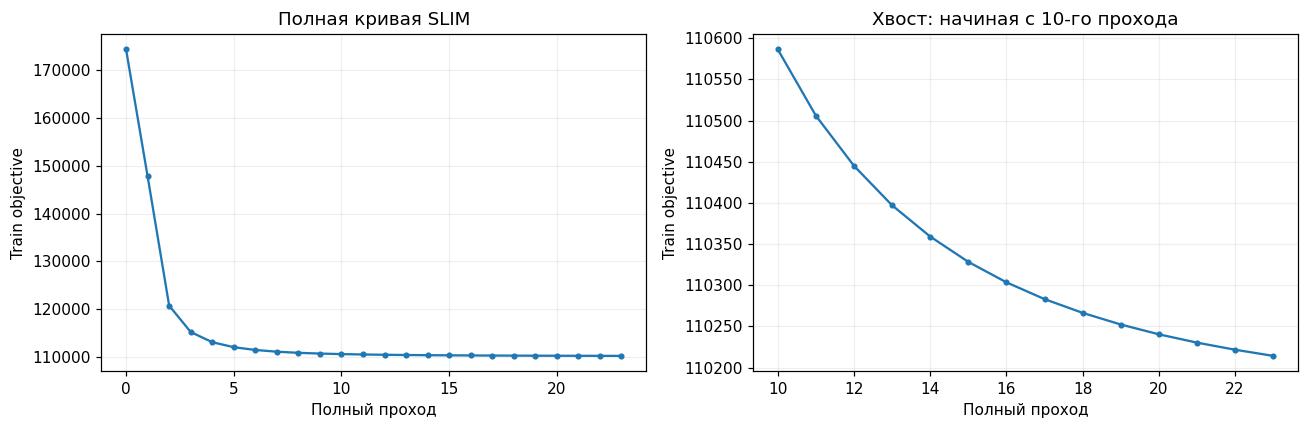

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
steps = np.array(slim.loss_steps)
losses = np.array(slim.loss_history)

axes[0].plot(steps, losses, marker='.')
axes[0].set(title='Полная кривая SLIM', xlabel='Полный проход', ylabel='Train objective')

tail = steps >= 10
axes[1].plot(steps[tail], losses[tail], marker='.')
axes[1].set(title='Хвост: начиная с 10-го прохода', xlabel='Полный проход', ylabel='Train objective')
axes[1].ticklabel_format(axis='y', style='plain', useOffset=False)

fig.tight_layout()
plt.show()

### FM

Признаки x: user ID, item ID, стиль, производитель и стандартизованный ABV.
Полная размерность — 5589.
$$f(x)=b+\sum_j w_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.$$
Обучаем MSE по всем наблюдённым явным оценкам с Adam и L2. Неизвестные пары не превращаются в оценки 0.
Метаданные фиксируются только по train.

**Гиперпараметры FM.** 
* $d = 16$, $lr = 0.01$, $L2 = 1e-5$, 6 эпох
* $d = 32$, $lr = 0.005$, $L2 = 1e-4$, 10 эпох

Размер батча - 2048.
Выбираем по validation NDCG@10, затем Recall@10.

In [48]:
fm_grid = [dict(n_factors=16, n_epochs=6, optimizer=dict(lr=.01, weight_decay=1e-5)),
           dict(n_factors=32, n_epochs=10, optimizer=dict(lr=.005, weight_decay=1e-4))]

loss = torch.nn.MSELoss()
fm, fm_choice, fm_trials = tune_model('FM', FactorizationMachine, fm_grid, data,
    validation_truth, validation_users, t_val, train_seen,
    loss=loss, optimizer=torch.optim.Adam, seed=SEED)

display(fm_trials)

FM 1/2: NDCG@10=0.02934, Recall@10=0.01362
FM 2/2: NDCG@10=0.04060, Recall@10=0.01843


,model,trial,parameters,fit_seconds,NDCG@10,Recall@10
0,FM,1,"{'n_factors': 16, 'n_epochs': 6, 'optimizer': {'lr': 0.01, 'weight_decay': 1e-05}}",2.029,0.029,0.014
1,FM,2,"{'n_factors': 32, 'n_epochs': 10, 'optimizer': {'lr': 0.005, 'weight_decay': 0.0001}}",4.795,0.041,0.018


**FM без метаданных.** Убираем стиль, производителя и ABV, оставляя user/item ID.
Для этой абляции используем те же два сочетания числа факторов, lr, L2 и эпох, что у основной FM,
и тот же критерий выбора на validation. Отзывы, разбиение и кандидаты остаются общими.

In [49]:
fm_id_grid = [dict(params, use_metadata=False) for params in fm_grid]

fm_id, fm_id_choice, fm_id_trials = tune_model('FM without metadata', FactorizationMachine,
    fm_id_grid, data, validation_truth, validation_users, t_val, train_seen,
    loss=loss, optimizer=torch.optim.Adam, seed=SEED)

display(fm_id_trials)

FM without metadata 1/2: NDCG@10=0.03179, Recall@10=0.01454
FM without metadata 2/2: NDCG@10=0.04080, Recall@10=0.01856


,model,trial,parameters,fit_seconds,NDCG@10,Recall@10
0,FM without metadata,1,"{'n_factors': 16, 'n_epochs': 6, 'optimizer': {'lr': 0.01, 'weight_decay': 1e-05}, 'use_metadata': False}",1.916,0.032,0.015
1,FM without metadata,2,"{'n_factors': 32, 'n_epochs': 10, 'optimizer': {'lr': 0.005, 'weight_decay': 0.0001}, 'use_metadata': False}",3.549,0.041,0.019


На графике одна точка соответствует одной эпохе обучения. Показываем среднюю train-MSE
мини-батчей, взвешенную по числу отзывов в каждом батче. Это ошибки, измеренные в ходе обучения,
а не повторный расчёт всего train при фиксированных параметрах после эпохи.
Штраф L2 применяется через `weight_decay` оптимизатора и в изображённую MSE не включён.

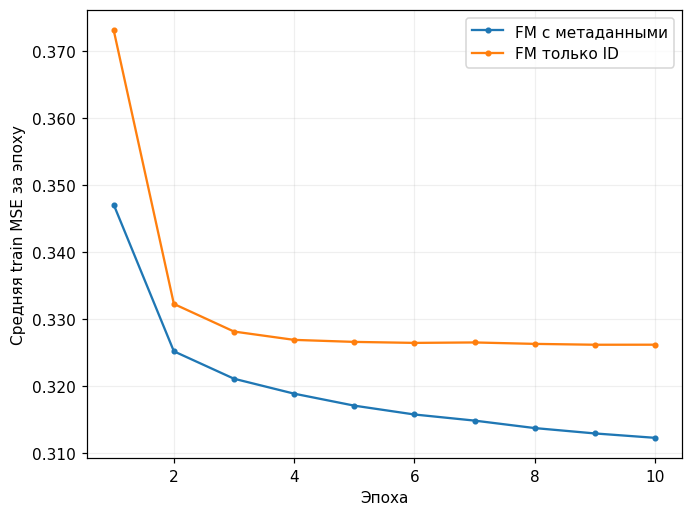

In [50]:
plot_losses({'FM с метаданными': fm, 'FM только ID': fm_id},
            'Эпоха', 'Средняя train MSE за эпоху')

**Динамика FM.** Средняя train-MSE уменьшается быстрее в первых эпохах, затем снижение замедляется.
На графике по эпохам колебания отдельных мини-батчей усредняются, поэтому кривая выглядит ровнее.
FM с метаданными имеет меньшую обучающую MSE, но качество top-10 сравниваем отдельно по NDCG@10
и Recall@10: уменьшение ошибки оценок не гарантирует улучшения ранжирования.

### timeSVD++

Добавляем временные пользовательские факторы, bias и положительную историю:
$$\hat r_{ui}(t)=\mu+b_i+b_{i,Bin(t)}+b_u+\alpha_u dev_u(t)+b_{u,day(t)}
+q_i^T\left[p_u+A_u dev_u(t)+p_{u,day(t)}+
|N_u(t)|^{-1/2}\sum_{j\in N_u(t)}y_j\right].$$
Здесь $dev_u(t)=sign(t-\bar t_u)(|t-\bar t_u|/365)^{0.4}$ в днях.
$N_u(t)$ - положительные train-отзывы строго раньше timestamp примера. При пустой истории её вклад равен 0.
Все наблюдённые оценки, включая низкие, входят в MSE. Обучаем с использованием Adam.

**Гиперпараметры timeSVD++.** 
* $d = 16$, 10 временных bins, 6 эпох, $lr = 0.005$
* $d = 32$, 20 bins, 10 эпох, $lr=0.003$

Для обоих вариантов $L2 = 1e-4$, размер батча - 2048.
Критерий выбора — validation NDCG@10, затем Recall@10.

In [51]:
time_grid = [dict(n_factors=16, n_bins=10, n_epochs=6, optimizer=dict(lr=.005, weight_decay=1e-4)),
             dict(n_factors=32, n_bins=20, n_epochs=10, optimizer=dict(lr=.003, weight_decay=1e-4))]

time_svd, time_choice, time_trials = tune_model('timeSVD++', TimeSVDPlusPlus, time_grid, data,
    validation_truth, validation_users, t_val, train_seen,
    loss=loss, optimizer=torch.optim.Adam, seed=SEED)

display(time_trials)

timeSVD++ 1/2: NDCG@10=0.04009, Recall@10=0.01927
timeSVD++ 2/2: NDCG@10=0.04276, Recall@10=0.01828


,model,trial,parameters,fit_seconds,NDCG@10,Recall@10
0,timeSVD++,1,"{'n_factors': 16, 'n_bins': 10, 'n_epochs': 6, 'optimizer': {'lr': 0.005, 'weight_decay': 0.0001}}",67.311,0.040,0.019
1,timeSVD++,2,"{'n_factors': 32, 'n_bins': 20, 'n_epochs': 10, 'optimizer': {'lr': 0.003, 'weight_decay': 0.0001}}",171.078,0.043,0.018


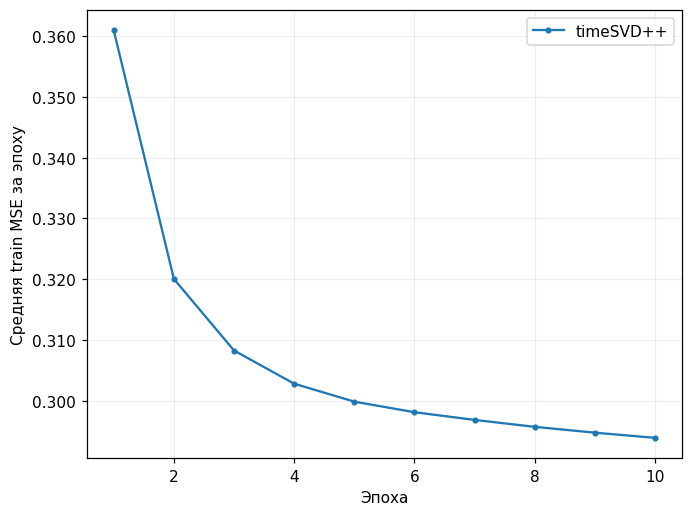

In [52]:
plot_losses({'timeSVD++': time_svd}, 'Эпоха', 'Средняя train MSE за эпоху')

**Динамика timeSVD++.** Основное снижение средней train-MSE происходит в первых эпохах;
затем модель продолжает улучшать обучающие предсказания медленнее. Каждая точка усредняет
мини-батчи всей эпохи, поэтому повторяющиеся внутри неё подъёмы loss здесь не отображаются.
Снижение train-MSE характеризует обучение регрессии оценок; качество рекомендаций проверяется
отдельно на validation и test.

## Оценка работы

Основная метрика NDCG@10 учитывает позиции релевантных напитков:
$$DCG_u@10=\sum_{r=1}^{10}\frac{\mathbb{1}[i_r\in R_u]}{\log_2(r+1)},\qquad
NDCG_u@10=\frac{DCG_u@10}{\sum_{r=1}^{\min(10,|R_u|)}1/\log_2(r+1)}.$$
Recall@10 — доля найденных релевантных напитков:
$$Recall_u@10=\frac{|Top10_u\cap R_u|}{|R_u|}.$$
При пустом $R_u$ метрики равны 0;
основной результат - макросреднее по фиксированной test-группе.

In [53]:
best_models = {'ItemKNN': knn, 'iALS': ials, 'SLIM': slim, 'FM': fm,
               'timeSVD++': time_svd, 'FM without metadata': fm_id}

validation_selected = pd.DataFrame([knn_choice, ials_choice, slim_choice, fm_choice,
                                    time_choice, fm_id_choice]).set_index('model', drop=False)
display(validation_selected[['model', 'NDCG@10', 'Recall@10', 'parameters']]
        .rename(columns={'NDCG@10': 'Validation NDCG@10', 'Recall@10': 'Validation Recall@10'}))

,model,Validation NDCG@10,Validation Recall@10,parameters
model,,,,
ItemKNN,ItemKNN,0.020,0.007,{'n_neighbors': 50}
iALS,iALS,0.067,0.028,"{'n_factors': 16, 'alpha': 10.0, 'regularization': 1.0, 'n_iterations': 10}"
SLIM,SLIM,0.078,0.030,"{'l1': 1.0, 'l2': 50.0, 'max_iter': 100, 'tol': 0.0001, 'patience': 3}"
FM,FM,0.041,0.018,"{'n_factors': 32, 'n_epochs': 10, 'optimizer': {'lr': 0.005, 'weight_decay': 0.0001}}"
timeSVD++,timeSVD++,0.043,0.018,"{'n_factors': 32, 'n_bins': 20, 'n_epochs': 10, 'optimizer': {'lr': 0.003, 'weight_decay': 0.0001}}"
FM without metadata,FM without metadata,0.041,0.019,"{'n_factors': 32, 'n_epochs': 10, 'optimizer': {'lr': 0.005, 'weight_decay': 0.0001}, 'use_metadata': False}"


In [54]:
test_truth = relevance_sets(test, test_users, CONFIG['threshold'])
test_seen = train_seen

active_test_users = sum(bool(x) for x in test_truth.values())
active_share = active_test_users / len(test_users)
print('Есть релевантные объекты в test:', active_test_users, '/', len(test_users))

Есть релевантные объекты в test: 955 / 2000


In [55]:
from utils import ranking_metrics

test_recommendations = {}
final_rows = []

for name, model in best_models.items():
    predictions = model.recommend(test_users, timestamps=t_test, seen_mask=test_seen, k=K)
    test_recommendations[name] = predictions
    metrics = ranking_metrics(predictions, test_truth, test_users, k=K)
    chosen = validation_selected.loc[name]
    final_rows.append({'model': name, **metrics, 'validation_NDCG@10': chosen[PRIMARY_METRIC],
                       'fit_seconds': chosen.fit_seconds, 'parameters': chosen.parameters})

results = pd.DataFrame(final_rows)
main_results = results.loc[results.model != 'FM without metadata'].sort_values(PRIMARY_METRIC, ascending=False)

In [56]:
test_columns = {'NDCG@10': 'Test NDCG@10', 'Recall@10': 'Test Recall@10'}

display(main_results[['model', 'NDCG@10', 'Recall@10', 'parameters']].rename(columns=test_columns))
display(results.loc[results.model.str.startswith('FM'), ['model', 'NDCG@10', 'Recall@10', 'parameters']]
        .rename(columns=test_columns))

,model,Test NDCG@10,Test Recall@10,parameters
2,SLIM,0.082,0.033,"{'l1': 1.0, 'l2': 50.0, 'max_iter': 100, 'tol': 0.0001, 'patience': 3}"
1,iALS,0.072,0.031,"{'n_factors': 16, 'alpha': 10.0, 'regularization': 1.0, 'n_iterations': 10}"
4,timeSVD++,0.046,0.022,"{'n_factors': 32, 'n_bins': 20, 'n_epochs': 10, 'optimizer': {'lr': 0.003, 'weight_decay': 0.0001}}"
3,FM,0.039,0.018,"{'n_factors': 32, 'n_epochs': 10, 'optimizer': {'lr': 0.005, 'weight_decay': 0.0001}}"
0,ItemKNN,0.019,0.007,{'n_neighbors': 50}


,model,Test NDCG@10,Test Recall@10,parameters
3,FM,0.039,0.018,"{'n_factors': 32, 'n_epochs': 10, 'optimizer': {'lr': 0.005, 'weight_decay': 0.0001}}"
5,FM without metadata,0.044,0.022,"{'n_factors': 32, 'n_epochs': 10, 'optimizer': {'lr': 0.005, 'weight_decay': 0.0001}, 'use_metadata': False}"


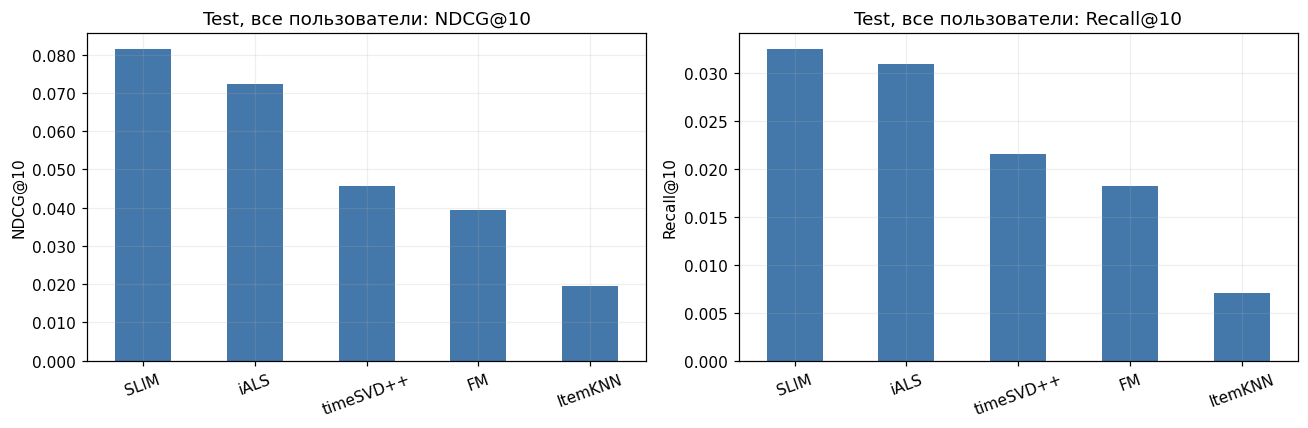

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    main_results.set_index('model')[metric].plot.bar(ax=ax, color='#4477AA', rot=20)
    ax.set(title=f'Test, все пользователи: {metric}', xlabel='', ylabel=metric)
    ax.yaxis.set_major_formatter('{x:.3f}')

fig.tight_layout()
plt.show()

**Метрики среди пользователей с релевантными объектами.** Отдельно берём только тех пользователей,
у которых на test есть хотя бы один напиток с оценкой $\geq 4$, и усредняем те же индивидуальные метрики.

In [58]:
relevant_user_mask = np.array([bool(test_truth[user]) for user in test_users])
relevant_users = test_users[relevant_user_mask]

conditional_metrics = pd.DataFrame([
    {'model': name, **ranking_metrics(test_recommendations[name][relevant_user_mask],
                                     test_truth, relevant_users, k=K)}
    for name in main_results.model
])
display(conditional_metrics.rename(columns=test_columns))

,model,Test NDCG@10,Test Recall@10
0,SLIM,0.171,0.068
1,iALS,0.152,0.065
2,timeSVD++,0.096,0.045
3,FM,0.082,0.038
4,ItemKNN,0.041,0.015


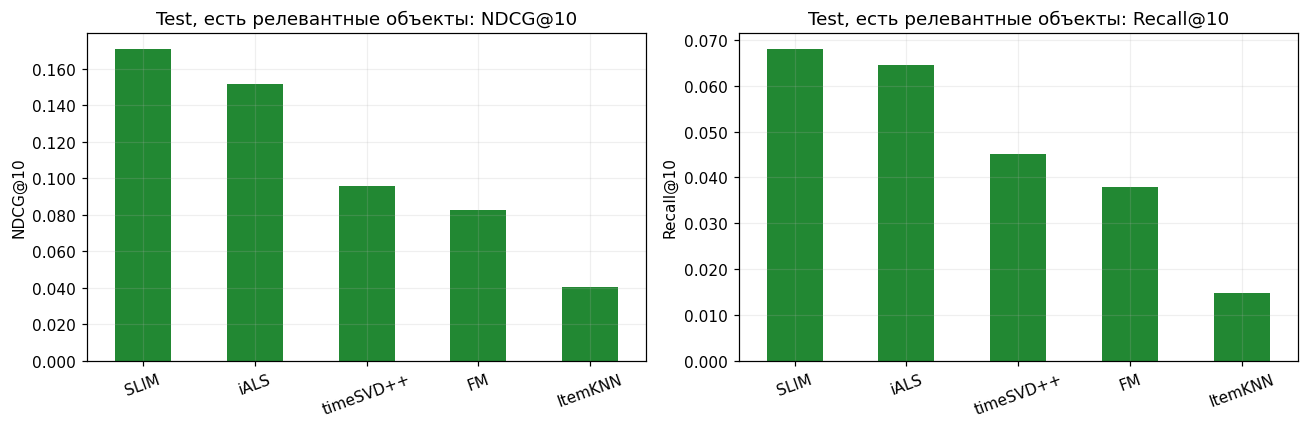

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['NDCG@10', 'Recall@10']):
    conditional_metrics.set_index('model')[metric].plot.bar(ax=ax, color='#228833', rot=20)
    ax.set(title=f'Test, есть релевантные объекты: {metric}', xlabel='', ylabel=metric)
    ax.yaxis.set_major_formatter('{x:.3f}')

fig.tight_layout()
plt.show()

### Рекомендации одному пользователю

Берём первого по порядку внутреннего ID пользователя из test-группы, у которого есть хотя бы
три релевантных test-объекта. Это заранее определённое правило для наглядного примера;
пользователь не подбирается по числу попаданий моделей. Сначала выводим все его релевантные
напитки, затем top-10 каждой из пяти моделей с выбранными на validation настройками.
Все выдачи построены в один момент `t_test`, с общими кандидатами и исключением уже известных пользователю объектов из train.
В таблицах флаг `relevant` показывает попадание в положительные test-отзывы; отсутствие попадания
означает отсутствие положительного test-события, а не обязательно то, что напиток не понравится.

In [60]:
example_user = next(user for user in test_users if len(test_truth[user]) >= 3)
example_position = int(np.flatnonzero(test_users == example_user)[0])
example_user_id = train.loc[train.user_idx == example_user, 'user_id'].iloc[0]

print(f'Пользователь: {example_user_id}, внутренний ID: {example_user}')
relevant_items = (test.loc[(test.user_idx == example_user) & (test.rating >= CONFIG['threshold']),
                           ['item_idx', 'rating', 'timestamp']]
                  .merge(metadata[['name', 'style']], left_on='item_idx', right_index=True)
                  .sort_values(['rating', 'item_idx'], ascending=[False, True]))
display(relevant_items.reset_index(drop=True))

Пользователь: 1759Girl, внутренний ID: 5


,item_idx,rating,timestamp,name,style
0,868,5.000,1297800737,Pliny The Younger,American Double / Imperial IPA
1,521,4.000,1289441626,Brown Shugga',American Strong Ale
2,611,4.000,1280693814,Éphémère (Apple),Fruit / Vegetable Beer
3,682,4.000,1285645563,Punkin Ale,Pumpkin Ale
4,912,4.000,1280974037,Noire De Chambly / Chambly Noire,Belgian Dark Ale
5,1048,4.000,1280973578,Serpent's Stout,American Double / Imperial Stout
6,1116,4.000,1288014869,Stone Cali-Belgique,Belgian IPA
7,1198,4.000,1288014991,Saison Du BUFF,Saison / Farmhouse Ale


In [61]:
example_hits = []

for name in main_results.model:
    item_ids = test_recommendations[name][example_position]
    item_ids = item_ids[item_ids >= 0]
    recommendations = metadata.loc[item_ids, ['name', 'style']].reset_index()
    recommendations.insert(0, 'rank', np.arange(1, len(item_ids) + 1))
    recommendations['relevant'] = recommendations.item_idx.isin(test_truth[example_user])

    print(name)
    display(recommendations)
    example_hits.append({'model': name, 'hits@10': int(recommendations.relevant.sum()),
                         'relevant_items': len(test_truth[example_user])})

display(pd.DataFrame(example_hits))

SLIM


,rank,item_idx,name,style,relevant
0,1,693,Northern Hemisphere Harvest Wet Hop Ale,American IPA,False
1,2,105,Sierra Nevada Porter,American Porter,False
2,3,563,Sierra Nevada Bigfoot Barleywine Style Ale,American Barleywine,False
3,4,1030,Hop Stoopid,American Double / Imperial IPA,False
4,5,148,Old Rasputin Russian Imperial Stout,Russian Imperial Stout,False
5,6,36,Samuel Adams Boston Lager,Vienna Lager,False
6,7,638,Stone Ruination IPA,American Double / Imperial IPA,False
7,8,1188,Samuel Adams Noble Pils,Czech Pilsener,False
8,9,1008,Ten FIDY,Russian Imperial Stout,False
9,10,439,St. Bernardus Abt 12,Quadrupel (Quad),False


iALS


,rank,item_idx,name,style,relevant
0,1,29,Arrogant Bastard Ale,American Strong Ale,False
1,2,1030,Hop Stoopid,American Double / Imperial IPA,False
2,3,725,Oaked Arrogant Bastard Ale,American Strong Ale,False
3,4,880,Green Flash West Coast I.P.A.,American IPA,False
4,5,638,Stone Ruination IPA,American Double / Imperial IPA,False
5,6,26,Stone IPA (India Pale Ale),American IPA,False
6,7,329,Santa's Private Reserve Ale,American Amber / Red Ale,False
7,8,503,90 Minute IPA,American Double / Imperial IPA,False
8,9,1024,Lagunitas Lucky 13 Mondo Large Red Ale,American Amber / Red Ale,False
9,10,521,Brown Shugga',American Strong Ale,True


timeSVD++


...

FM


,rank,item_idx,name,style,relevant
0,1,398,Trappist Westvleteren 12,Quadrupel (Quad),False
1,2,885,Portsmouth Kate The Great,Russian Imperial Stout,False
2,3,1007,The Abyss,American Double / Imperial Stout,False
3,4,706,Dark Lord Imperial Stout,Russian Imperial Stout,False
4,5,987,Darkness,Russian Imperial Stout,False
5,6,868,Pliny The Younger,American Double / Imperial IPA,True
6,7,1004,Cuvee De Tomme,American Wild Ale,False
7,8,995,B.O.R.I.S. The Crusher Oatmeal-Imperial Stout,Russian Imperial Stout,False
8,9,688,Masala Mama India Pale Ale,American IPA,False
9,10,953,Sculpin India Pale Ale,American IPA,False


ItemKNN


,rank,item_idx,name,style,relevant
0,1,195,Guinness Extra Stout (Original),Irish Dry Stout,False
1,2,208,Brooklyn Black Chocolate Stout,Russian Imperial Stout,False
2,3,219,Big Eye IPA,American IPA,False
3,4,244,Samuel Smith's Imperial Stout,Russian Imperial Stout,False
4,5,338,Kapuziner Weissbier,Hefeweizen,False
5,6,460,St. Bernardus Pater 6,Dubbel,False
6,7,469,Third Coast Old Ale,American Barleywine,False
7,8,518,Bush De Noël,Belgian Strong Dark Ale,False
8,9,553,Cantillon Rosé De Gambrinus,Lambic - Fruit,False
9,10,626,Trappistes Rochefort 6,Belgian Strong Dark Ale,False


,model,hits@10,relevant_items
0,SLIM,0,8
1,iALS,1,8
2,timeSVD++,1,8
3,FM,1,8
4,ItemKNN,0,8


Видим, что некоторые модели попали в релевантные для пользователя объекты.

## Выводы

В ходе домашней работы обучили и сравнили 5 моделей (ItemKNN, iALS, SLIM, FM и timeSVD++)
на датасете **BeerAdvocate**, содержащем отзывы 4000 пользователей о 1200 напитках.

Гиперпараметры выбирали по validation NDCG@10, итоговое качество оценивали на test
по NDCG@10 и Recall@10. Для всех экспериментов зафиксировали `seed=52`.

Лучший результат на test получил **SLIM** с $L1=1$ и $L2=50$:
**NDCG@10=0.082, Recall@10=0.033**. Второе место занял iALS
(NDCG@10=0.072, Recall@10=0.031).
Среди 955 test-пользователей с релевантными объектами у SLIM NDCG@10=0.171 и Recall@10=0.068.

Метаданные не улучшили FM: NDCG@10=0.039 с ними против 0.044 только с ID.
timeSVD++ получил NDCG@10=0.046 и уступил iALS и SLIM.
Таким образом, в этом эксперименте лучшие рекомендации дали коллаборативные модели iALS и SLIM.